# Part B: H2O AutoML on the athletes data

**Goal:** let H2O AutoML try many models for us, then compare them with our hand-built Part A model.

**What is AutoML?** Instead of choosing one algorithm and settings ourselves (Part A), AutoML trains many models (gradient boosting, random forests, linear models, ensembles), scores them all the same way, and ranks them on a **leaderboard**.

**Same data as Part A:** the v2 training table from the feature store, same 80/20 athletes, target `total_lift`. Created by `python src/export_automl_data.py`.

Run this notebook from the project folder with the project `.venv` selected as the kernel. H2O needs Java.

In [ ]:
import os, time, sys
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import h2o
from h2o.automl import H2OAutoML, get_leaderboard
from codecarbon import OfflineEmissionsTracker

ROOT = Path.cwd()
if not (ROOT / "data").exists():          # opened from the notebooks/ folder
    ROOT = ROOT.parent
DATA = ROOT / "data" / "automl"
OUT = ROOT / "reports" / "automl"
(OUT / "emissions").mkdir(parents=True, exist_ok=True)

TARGET, SEED = "total_lift", 42
MAX_MODELS = int(os.environ.get("H2O_MAX_MODELS", 10))        # how many individual models to try
MAX_SECONDS = int(os.environ.get("H2O_MAX_SECONDS", 300))     # hard time cap per AutoML run
print("h2o", h2o.__version__, "| data folder:", DATA)

h2o 3.46.0.12 | data folder: /Users/yin/Downloads/MLops/hw2/data/automl


## 1. Start H2O

`h2o.init()` starts a small Java server on your machine. Python sends it data and commands. (If this fails with a connection error, Java is missing or too new: install Java 17.)

In [ ]:
# H2O is picky about Java. If Java 17 is installed with Homebrew, use it (Java 20 and newer can fail to start H2O).
for home in ["/opt/homebrew/opt/openjdk@17", "/usr/local/opt/openjdk@17"]:
    if os.path.exists(home + "/bin/java"):
        os.environ["JAVA_HOME"] = home
        os.environ["PATH"] = home + "/bin:" + os.environ["PATH"]
        print("using Java 17 from", home)
        break
else:
    print("Java 17 not found in the usual Homebrew folders; using whatever Java is on your PATH")
h2o.init(max_mem_size='4G')

using Java 17 from /opt/homebrew/opt/openjdk@17
Checking whether there is an H2O instance running at http://localhost:54321..... not found.
Attempting to start a local H2O server...
  Java Version: openjdk version "17.0.21.0.3" 2026-10-24; OpenJDK Runtime Environment Homebrew (build 17.0.21.0.3+0); OpenJDK 64-Bit Server VM Homebrew (build 17.0.21.0.3+0, mixed mode, sharing)
  Starting server from /Users/yin/Downloads/MLops/hw2/.venv/lib/python3.12/site-packages/h2o/backend/bin/h2o.jar
  Ice root: /var/folders/d8/tlppmszs12sd_z9k_9lyqr3w0000gn/T/tmpy6dznnue
  JVM stdout: /var/folders/d8/tlppmszs12sd_z9k_9lyqr3w0000gn/T/tmpy6dznnue/h2o_yin_started_from_python.out
  JVM stderr: /var/folders/d8/tlppmszs12sd_z9k_9lyqr3w0000gn/T/tmpy6dznnue/h2o_yin_started_from_python.err
  Server is running at http://127.0.0.1:54321
Connecting to H2O server at http://127.0.0.1:54321 ... successful.


H2O_cluster_uptime:,03 secs
H2O_cluster_timezone:,America/Chicago
H2O_data_parsing_timezone:,UTC
H2O_cluster_version:,3.46.0.12
H2O_cluster_version_age:,2 months and 29 days
H2O_cluster_name:,H2O_from_python_yin_w1kwvq
H2O_cluster_total_nodes:,1
H2O_cluster_free_memory:,4 Gb
H2O_cluster_total_cores:,10
H2O_cluster_allowed_cores:,10
H2O_cluster_status:,"locked, healthy"



+------------------------------------------------------------------+
| You are running the community edition of H2O-3 OSS.              |
|                                                                  |
| For commercial use, H2O-3 Secure is now recommended.             |
| This includes production support, CVE fixes, multi-node scaling, |
| model artifact extraction, and more.                             |
| See h2o.ai/h2o-3/oss-vs-secure for additional details.           |
| Contact enterprise@h2o.ai to upgrade.                            |
+------------------------------------------------------------------+


## 2. Load the data (same athletes as Part A)

In [ ]:
train_df = pd.read_csv(DATA / "athletes_v2_train.csv")
test_df = pd.read_csv(DATA / "athletes_v2_test.csv")
print("train", train_df.shape, "| test", test_df.shape)
train_df.head(3)

train (24041, 16) | test (6011, 16)


,total_lift,age,height,weight,is_male,bmi,howlong_years,bg_college_sports,bg_no_athletic,exp_started_with_coach,exp_level1_cert,exp_trains_others,sched_multi_per_day,eat_weigh_measure,eat_paleo,region
0,1110.0,30.0,71.0,200.0,1,27.891291,1.50,1,0,0,0,0,1,0,0,Southern California
1,760.0,24.0,71.0,167.0,1,23.289228,0.25,0,1,1,0,0,0,0,0,Europe
2,793.0,28.0,72.0,167.0,1,22.646798,0.75,0,0,0,0,0,1,0,0,Europe


In [ ]:
train = h2o.H2OFrame(train_df, destination_frame="train")
test = h2o.H2OFrame(test_df, destination_frame="test")
train["region"] = train["region"].asfactor()      # text column -> categorical
test["region"] = test["region"].asfactor()
ALL_FEATURES = [c for c in train.columns if c != TARGET]
print(len(ALL_FEATURES), "features:", ALL_FEATURES)

Parse progress: |████████████████████████████████████████████████████████████████| (done) 100%
Parse progress: |████████████████████████████████████████████████████████████████| (done) 100%
15 features: ['age', 'height', 'weight', 'is_male', 'bmi', 'howlong_years', 'bg_college_sports', 'bg_no_athletic', 'exp_started_with_coach', 'exp_level1_cert', 'exp_trains_others', 'sched_multi_per_day', 'eat_weigh_measure', 'eat_paleo', 'region']


## 3. Quick data insights

AutoML tools profile the data first. Here are the basics that matter for this dataset.

In [ ]:
print(train_df[TARGET].describe().round(1).to_string())
print("\nmissing values:", int(train_df.isna().sum().sum()))
corr = train_df.drop(columns="region").corr()[TARGET].drop(TARGET).sort_values()
print("\ncorrelation with total_lift:\n", corr.round(2).to_string())
print("\nmean total_lift by sex (1 = male):", train_df.groupby("is_male")[TARGET].mean().round(0).to_dict())

count    24041.0
mean      1018.3
std        277.0
min         80.0
25%        805.0
50%       1040.0
75%       1225.0
max       2030.0

missing values: 0

correlation with total_lift:
 exp_started_with_coach   -0.27
bg_no_athletic           -0.22
age                      -0.14
eat_paleo                -0.04
eat_weigh_measure        -0.03
howlong_years             0.17
bg_college_sports         0.17
exp_level1_cert           0.23
sched_multi_per_day       0.23
exp_trains_others         0.25
bmi                       0.43
height                    0.53
weight                    0.62
is_male                   0.72

mean total_lift by sex (1 = male): {0: 693.0, 1: 1140.0}


## 4. Run AutoML with ALL features

`max_models` limits how many individual models; `max_runtime_secs` is a safety time cap; `nfolds=5` means every model is scored with 5-fold cross-validation (this is the **validation score**); `sort_metric="RMSE"` ranks by error (lower is better), the same metric as Part A.

In [ ]:
def run_automl(features, label):
    tracker = OfflineEmissionsTracker(country_iso_code="USA", project_name=label, log_level="error",
                                      output_dir=str(OUT / "emissions"), output_file="emissions.csv")
    aml = H2OAutoML(max_models=MAX_MODELS, max_runtime_secs=MAX_SECONDS, nfolds=5, seed=SEED,
                    sort_metric="RMSE", project_name=label, verbosity="warn")
    tracker.start()
    t0 = time.perf_counter()
    aml.train(x=features, y=TARGET, training_frame=train)
    seconds = time.perf_counter() - t0
    co2 = tracker.stop() or 0.0
    return aml, seconds, co2

aml_all, secs_all, co2_all = run_automl(ALL_FEATURES, "h2o_all_features")
print(f"all features: {secs_all:.0f}s total, {co2_all*1e6:.1f} mg CO2e")

AutoML progress: |
02:41:25.724: AutoML: XGBoost is not available; skipping it.

███████████████████████████████████████████████████████████████| (done) 100%
all features: 41s total, 247.4 mg CO2e


## 5. The leaderboard

`extra_columns="ALL"` adds **training_time_ms** (how long each model took to train) and **predict_time_per_row_ms** (how fast it predicts). `rmse` here is the cross-validation (validation) RMSE.

In [ ]:
def leaderboard(aml):
    return get_leaderboard(aml, extra_columns="ALL").as_data_frame()

lb_all = leaderboard(aml_all)
lb_all[["model_id", "rmse", "mae", "training_time_ms", "predict_time_per_row_ms"]].round(4)

/Users/yin/Downloads/MLops/hw2/.venv/lib/python3.12/site-packages/h2o/frame.py:1983: H2ODependencyWarning: Converting H2O frame to pandas dataframe using single-thread.  For faster conversion using multi-thread, install polars and pyarrow and use it as pandas_df = h2o_df.as_data_frame(use_multi_thread=True)

  warnings.warn("Converting H2O frame to pandas dataframe using single-thread.  For faster conversion using"


,model_id,rmse,mae,training_time_ms,predict_time_per_row_ms
0,StackedEnsemble_AllModels_1_AutoML_1_20261110_...,139.4614,107.8098,761,0.0235
1,StackedEnsemble_BestOfFamily_1_AutoML_1_202611...,139.7352,108.0380,1011,0.0237
2,GBM_5_AutoML_1_20261110_24125,139.9451,108.2219,235,0.0080
3,GBM_grid_1_AutoML_1_20261110_24125_model_1,140.3958,108.6418,258,0.0075
4,GBM_2_AutoML_1_20261110_24125,140.3976,108.6063,229,0.0082
5,GBM_1_AutoML_1_20261110_24125,140.7270,108.8479,762,0.0106
6,GBM_3_AutoML_1_20261110_24125,140.9790,108.9961,255,0.0086
7,GBM_4_AutoML_1_20261110_24125,142.4990,110.3674,405,0.0097
8,DRF_1_AutoML_1_20261110_24125,144.7421,112.1670,2939,0.0238
9,GLM_1_AutoML_1_20261110_24125,149.7559,116.0053,165,0.0002


### Top 3 models by validation score (lowest cross-validation RMSE) and by speed (shortest training time)

In [ ]:
def top3(lb, label):
    cols = ["model_id", "rmse", "training_time_ms", "predict_time_per_row_ms"]
    best = lb.nsmallest(3, "rmse")[cols]
    fast = lb.nsmallest(3, "training_time_ms")[cols]
    print(f"--- {label}: top 3 by validation RMSE ---"); print(best.round(3).to_string(index=False))
    print(f"\n--- {label}: top 3 by speed (training time) ---"); print(fast.round(3).to_string(index=False))
    return best, fast

best_all, fast_all = top3(lb_all, "ALL features")

--- ALL features: top 3 by validation RMSE ---
                                              model_id    rmse  training_time_ms  predict_time_per_row_ms
   StackedEnsemble_AllModels_1_AutoML_1_20261110_24125 139.461               761                    0.024
StackedEnsemble_BestOfFamily_1_AutoML_1_20261110_24125 139.735              1011                    0.024
                         GBM_5_AutoML_1_20261110_24125 139.945               235                    0.008

--- ALL features: top 3 by speed (training time) ---
                     model_id    rmse  training_time_ms  predict_time_per_row_ms
GLM_1_AutoML_1_20261110_24125 149.756               165                    0.000
GBM_2_AutoML_1_20261110_24125 140.398               229                    0.008
GBM_5_AutoML_1_20261110_24125 139.945               235                    0.008


## 6. Top 5 features (variable importance)

Stacked ensembles do not report importance, so we take the best tree model on the leaderboard.

importance taken from: GBM_5_AutoML_1_20261110_24125
         variable  relative_importance  percentage
          is_male         3796600320.0       0.537
           weight         1066397056.0       0.151
              bmi          602905920.0       0.085
              age          313424160.0       0.044
           height          296097504.0       0.042
    howlong_years          192753184.0       0.027
exp_trains_others          165850928.0       0.023
  exp_level1_cert          145095104.0       0.021

Top 5: ['is_male', 'weight', 'bmi', 'age', 'height'] 
Top 3 (used for the next run): ['is_male', 'weight', 'bmi']


/Users/yin/Downloads/MLops/hw2/.venv/lib/python3.12/site-packages/h2o/frame.py:1983: H2ODependencyWarning: Converting H2O frame to pandas dataframe using single-thread.  For faster conversion using multi-thread, install polars and pyarrow and use it as pandas_df = h2o_df.as_data_frame(use_multi_thread=True)

  warnings.warn("Converting H2O frame to pandas dataframe using single-thread.  For faster conversion using"


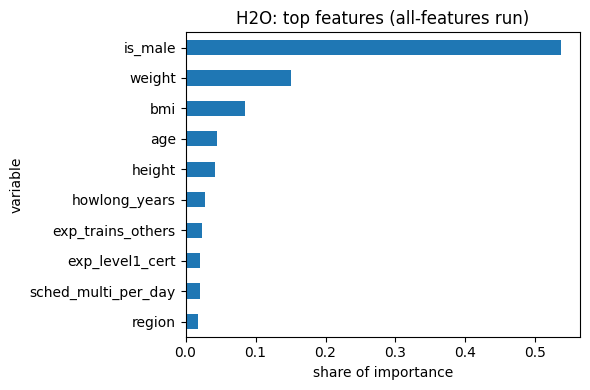

In [ ]:
def top_features(aml):
    for mid in aml.leaderboard.as_data_frame()["model_id"]:
        vi = h2o.get_model(mid).varimp(use_pandas=True)
        if vi is not None:
            return mid, vi
    raise RuntimeError("no model with variable importance")

vi_model, vi_all = top_features(aml_all)
print("importance taken from:", vi_model)
print(vi_all.head(8)[["variable", "relative_importance", "percentage"]].round(3).to_string(index=False))
TOP5 = vi_all["variable"].head(5).tolist()
TOP3 = vi_all["variable"].head(3).tolist()
print("\nTop 5:", TOP5, "\nTop 3 (used for the next run):", TOP3)

ax = vi_all.head(10).iloc[::-1].plot.barh(x="variable", y="percentage", legend=False, figsize=(6, 4))
ax.set(xlabel="share of importance", title="H2O: top features (all-features run)")
plt.tight_layout(); plt.savefig(OUT / "h2o_feature_importance.png", dpi=120); plt.show()

## 7. Run AutoML again with ONLY the top 3 features

In [ ]:
aml_top, secs_top, co2_top = run_automl(TOP3, "h2o_top3_features")
print(f"top-3 features: {secs_top:.0f}s total, {co2_top*1e6:.1f} mg CO2e")
lb_top = leaderboard(aml_top)
best_top, fast_top = top3(lb_top, "TOP-3 features")

AutoML progress: |
02:42:10.631: AutoML: XGBoost is not available; skipping it.

███████████████████████████████████████████████████████████████| (done) 100%
top-3 features: 12s total, 55.5 mg CO2e
--- TOP-3 features: top 3 by validation RMSE ---
                                              model_id    rmse  training_time_ms  predict_time_per_row_ms
   StackedEnsemble_AllModels_1_AutoML_2_20261110_24210 173.777               650                    0.011
StackedEnsemble_BestOfFamily_1_AutoML_2_20261110_24210 173.927               589                    0.005
            GBM_grid_1_AutoML_2_20261110_24210_model_1 174.002               111                    0.006

--- TOP-3 features: top 3 by speed (training time) ---
                                  model_id    rmse  training_time_ms  predict_time_per_row_ms
             GLM_1_AutoML_2_20261110_24210 182.329                31                    0.000
             GBM_5_AutoML_2_20261110_24210 174.111               104                 

/Users/yin/Downloads/MLops/hw2/.venv/lib/python3.12/site-packages/h2o/frame.py:1983: H2ODependencyWarning: Converting H2O frame to pandas dataframe using single-thread.  For faster conversion using multi-thread, install polars and pyarrow and use it as pandas_df = h2o_df.as_data_frame(use_multi_thread=True)

  warnings.warn("Converting H2O frame to pandas dataframe using single-thread.  For faster conversion using"


## 8. Test-set score of each run's best model

The leaderboard uses cross-validation on training athletes. Here we score the winner on the same 6,015 test athletes Part A used.

In [ ]:
def test_scores(aml, label):
    perf = aml.leader.model_performance(test)
    return {"run": label, "best_model": aml.leader.model_id, "test_rmse": perf.rmse(), "test_mae": perf.mae(), "test_r2": perf.r2()}

scores = pd.DataFrame([test_scores(aml_all, "h2o_all_features"), test_scores(aml_top, "h2o_top3_features")])
scores

,run,best_model,test_rmse,test_mae,test_r2
0,h2o_all_features,StackedEnsemble_AllModels_1_AutoML_1_20261110_...,138.601507,106.913987,0.748761
1,h2o_top3_features,StackedEnsemble_AllModels_1_AutoML_2_20261110_...,172.610787,135.682739,0.610340


## 9. Compare with Part A

Part A's best run (`v2_small`, gradient boosting) was trained once with our own settings. To compare **validation** scores fairly, we compute a 5-fold cross-validated RMSE for the same model on the same training athletes. Speed = time to train.

In [ ]:
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import GradientBoostingRegressor
from sklearn.model_selection import cross_val_score
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder

X, y = train_df.drop(columns=TARGET), train_df[TARGET]
pipe = Pipeline([("prep", ColumnTransformer([("cat", OneHotEncoder(handle_unknown="ignore", sparse_output=False), ["region"])],
                                            remainder="passthrough")),
                 ("model", GradientBoostingRegressor(n_estimators=100, max_depth=3, learning_rate=0.10, random_state=SEED))])
cv_rmse = -cross_val_score(pipe, X, y, cv=5, scoring="neg_root_mean_squared_error").mean()
part_a = pd.read_csv(ROOT / "reports" / "results.csv").set_index("run_name").loc["v2_small"]
print(f"Part A v2_small: 5-fold CV RMSE {cv_rmse:.1f} | test RMSE {part_a['rmse']:.1f} | single fit+predict {part_a['fit_predict_seconds']:.1f}s")

Part A v2_small: 5-fold CV RMSE 147.8 | test RMSE 139.4 | single fit+predict 1.7s


In [ ]:
rows = [{"approach": "Part A v2_small (hand-built)", "validation_rmse": cv_rmse, "test_rmse": part_a["rmse"],
         "train_seconds": part_a["fit_predict_seconds"], "co2e_mg": part_a["emissions_kg_co2e"] * 1e6}]
for label, lb, sc, secs, co2 in [("H2O all features", lb_all, scores.iloc[0], secs_all, co2_all),
                                 ("H2O top-3 features", lb_top, scores.iloc[1], secs_top, co2_top)]:
    rows.append({"approach": f"{label} ({sc.best_model.split('_')[0]})", "validation_rmse": lb.iloc[0]["rmse"],
                 "test_rmse": sc.test_rmse, "train_seconds": secs, "co2e_mg": co2 * 1e6})
comparison = pd.DataFrame(rows)
comparison.to_csv(OUT / "h2o_comparison.csv", index=False)
lb_all.to_csv(OUT / "h2o_leaderboard_all.csv", index=False)
lb_top.to_csv(OUT / "h2o_leaderboard_top3.csv", index=False)
comparison.round(2)

,approach,validation_rmse,test_rmse,train_seconds,co2e_mg
0,Part A v2_small (hand-built),147.79,139.45,1.70,2.11
1,H2O all features (StackedEnsemble),139.46,138.60,41.08,247.45
2,H2O top-3 features (StackedEnsemble),173.78,172.61,11.62,55.54


## 10. Is H2O AutoML no-code, low-code or full-code?

**Full-code.** We wrote Python to load data, set parameters, run `H2OAutoML`, and read the results. AutoML removes the work of choosing and tuning models, but we still program everything around it. (DataRobot, by contrast, is mostly point-and-click.)

In [ ]:
h2o.cluster().shutdown(prompt=False)

H2O session _sid_a3ef closed.
